# Steel Surface Defect Classification with a CNN

My aim was to identify the type of defect in an image of hot-rolled steel.So i created this model. This model learns to distinguish six defect types from their surface patterns.


1.libraries

The first cell checks for the two extra packages used in the course examples. The second cell imports the libraries and checks whether a GPU is available.

In [ ]:
from importlib.util import find_spec
import subprocess
import sys

missing_packages = [name for name in ("kagglehub", "torchsummary") if find_spec(name) is None]
if missing_packages:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing_packages], check=True)

In [ ]:
from copy import deepcopy
from hashlib import sha256
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, Subset
from torchsummary import summary
from torchvision import datasets, transforms

seed = 42
torch.manual_seed(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

print("Device:", device)

Device: cpu


2.Dataset

By Kechen Song and Yunhui Yan
Six kinds of typical surface defects of the hot-rolled steel strip are collected, i.e., rolled-in scale (RS), patches (Pa), crazing (Cr), pitted surface (PS), inclusion (In) and scratches (Sc). The database includes 1,800 grayscale images: 300(split into 240 images for training and 60 images for testing.) samples each of six different kinds of typical surface defects. This project uses the folder labels for image classification.

[Dataset on Kaggle](https://www.kaggle.com/datasets/kaustubhdikshit/neu-surface-defect-database) · [Original dataset description](https://faculty.neu.edu.cn/songkc/en/zdylm/263265/list/) · [Song and Yan (2013)](https://doi.org/10.1016/j.apsusc.2013.09.002)

In [3]:
path = Path(kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database/versions/1"
))
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Path to dataset files: /kaggle/input/neu-surface-defect-database


3. Prepared the images and data loaders

I use the archive's `train` folder to create the training and validation sets. The archive's separate `validation` folder is reserved for final testing. One exact duplicate is removed from the development images before splitting. The validation split is stratified, which keeps the class counts balanced.

In [4]:
train_folder = path / "NEU-DET" / "train" / "images"
test_folder = path / "NEU-DET" / "validation" / "images"

development_data = datasets.ImageFolder(train_folder)
holdout_data = datasets.ImageFolder(test_folder)
class_names = [name.replace("_", " ") for name in development_data.classes]

assert development_data.class_to_idx == holdout_data.class_to_idx
assert (len(development_data), len(holdout_data)) == (1440, 360)


def image_hash(file_path):
    with Image.open(file_path) as image:
        return sha256(image.convert("L").tobytes()).digest()


# Skip exact copies before making the training and validation sets.
seen_images = {}
unique_indices = []
for index, (file_path, label) in enumerate(development_data.samples):
    fingerprint = image_hash(file_path)
    if fingerprint in seen_images:
        assert seen_images[fingerprint] == label
        print("Duplicate removed:", Path(file_path).name)
        continue
    seen_images[fingerprint] = label
    unique_indices.append(index)

test_hashes = {image_hash(file_path) for file_path, _ in holdout_data.samples}
assert len(test_hashes) == len(holdout_data)
assert seen_images.keys().isdisjoint(test_hashes)

labels = np.asarray(development_data.targets)
train_indices, val_indices = train_test_split(
    unique_indices, test_size=240, random_state=seed, stratify=labels[unique_indices]
)
assert set(train_indices).isdisjoint(val_indices)

Duplicate removed: patches_105.jpg


I resized the images to 96 × 96 so the CNN can train quickly . Flips and mild contrast changes are applied to training images. The validation and test images use the same fixed preprocessing.

In [6]:
size = 96

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
])

val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
])

train_data = Subset(datasets.ImageFolder(train_folder, transform=train_transform), train_indices)
val_data = Subset(datasets.ImageFolder(train_folder, transform=val_transform), val_indices)
test_data = datasets.ImageFolder(test_folder, transform=val_transform)

In [7]:
print("Dataset summary")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))
print("Class labels:", dict(enumerate(class_names)))

test_labels = np.asarray(test_data.targets)
print(f"{'Class':<18}{'Train':>7}{'Val':>7}{'Test':>7}")
for class_id, name in enumerate(class_names):
    train_count = (labels[train_indices] == class_id).sum()
    val_count = (labels[val_indices] == class_id).sum()
    test_count = (test_labels == class_id).sum()
    print(f"{name:<18}{train_count:>7}{val_count:>7}{test_count:>7}")

Dataset summary
Training: 1199
Validation: 240
Test: 360
Class labels: {0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted surface', 4: 'rolled-in scale', 5: 'scratches'}
Class               Train    Val   Test
crazing               200     40     60
inclusion             200     40     60
patches               199     40     60
pitted surface        200     40     60
rolled-in scale       200     40     60
scratches             200     40     60


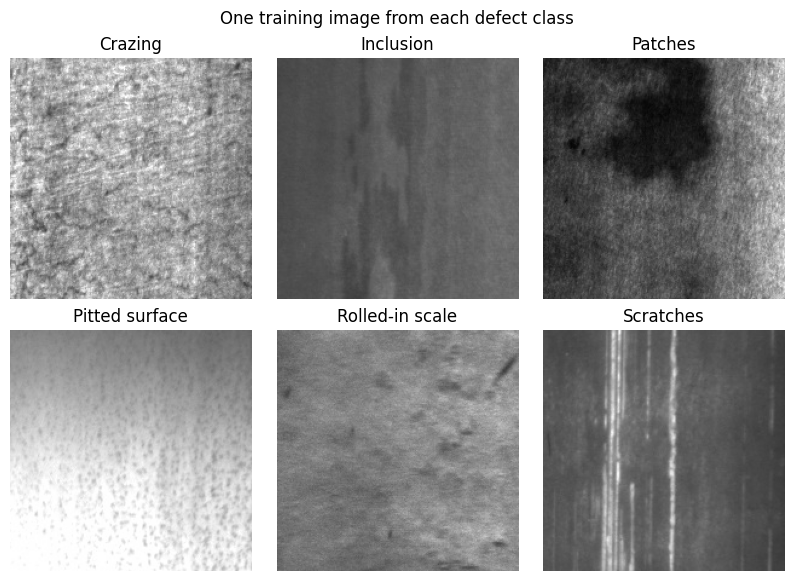

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(8, 5.7), layout="constrained")
sample_rng = np.random.default_rng(seed)

for class_id, ax in enumerate(axes.flat):
    candidates = [index for index in train_indices if labels[index] == class_id]
    image, _ = development_data[int(sample_rng.choice(candidates))]
    ax.imshow(image.convert("L"), cmap="gray", vmin=0, vmax=255)
    ax.set_title(class_names[class_id].capitalize())
    ax.axis("off")

fig.suptitle("One training image from each defect class")
plt.show()

use of Adam :
A batch size of 32 keeps memory use modest. Adam starts with a learning rate of 0.001, and 12 epochs give us enough points to compare the training and validation curves. The loader shuffles the training images each epoch.

In [9]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 12

trn_dl = DataLoader(
    train_data, batch_size=batch_size, shuffle=True,
    generator=torch.Generator().manual_seed(seed)
)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False)

4.CNN

The three convolution blocks learn image features at different scales. Each max-pooling layer halves the width and height. Adaptive average pooling gives the classifier a small 4 × 4 grid of features. Dropout helps reduce overfitting. The final layer returns six raw scores for cross-entropy loss.

In [10]:
def get_model():
    model = nn.Sequential(
        # Feature extraction
        nn.Conv2d(1, 16, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.AdaptiveAvgPool2d((4, 4)),
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 64),
        nn.ReLU(),
        nn.Dropout(0.20),
        nn.Linear(64, len(class_names)),
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

5. Train and validate the CNN

`train_one_epoch()` updates the weights. `validation()` measures loss and accuracy with the model in evaluation mode. Both functions weight the loss by the number of images in each batch so the final, smaller batch counts correctly.

In [11]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    loss_total = 0.0
    correct = 0

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        prediction = model(x)
        loss = loss_fn(prediction, y)
        loss.backward()
        optimizer.step()

        loss_total += loss.item() * y.size(0)
        correct += (prediction.argmax(dim=1) == y).sum().item()

    count = len(data_loader.dataset)
    return loss_total / count, correct / count


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    loss_total = 0.0
    correct = 0

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        loss_total += loss_fn(prediction, y).item() * y.size(0)
        correct += (prediction.argmax(dim=1) == y).sum().item()

    count = len(data_loader.dataset)
    return loss_total / count, correct / count

In [12]:
model, loss_fn, optimizer = get_model()
model.eval()

# Keep the summary's dummy input from changing the training seed.
with torch.random.fork_rng(devices=[]):
    summary(model, input_size=(1, size, size), device=device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 96, 96]             144
       BatchNorm2d-2           [-1, 16, 96, 96]              32
              ReLU-3           [-1, 16, 96, 96]               0
         MaxPool2d-4           [-1, 16, 48, 48]               0
            Conv2d-5           [-1, 32, 48, 48]           4,608
       BatchNorm2d-6           [-1, 32, 48, 48]              64
              ReLU-7           [-1, 32, 48, 48]               0
         MaxPool2d-8           [-1, 32, 24, 24]               0
            Conv2d-9           [-1, 64, 24, 24]          18,432
      BatchNorm2d-10           [-1, 64, 24, 24]             128
             ReLU-11           [-1, 64, 24, 24]               0
        MaxPool2d-12           [-1, 64, 12, 12]               0
AdaptiveAvgPool2d-13             [-1, 64, 4, 4]               0
          Flatten-14                 [-

In [13]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
best_val_loss = float("inf")

for epoch in range(epoch_number):
    train_loss, train_acc = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    val_loss, val_acc = validation(val_dl, model, loss_fn)

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_weights = deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train loss: {train_loss:.4f} | Train accuracy: {train_acc:.2%}"
        f" | Val loss: {val_loss:.4f} | Val accuracy: {val_acc:.2%}",
        flush=True,
    )

print(f"Selected epoch: {best_epoch} (validation loss {best_val_loss:.4f})")

Epoch [1/12] | Train loss: 0.9876 | Train accuracy: 65.39% | Val loss: 2.6557 | Val accuracy: 29.17%
Epoch [2/12] | Train loss: 0.5375 | Train accuracy: 81.23% | Val loss: 0.4474 | Val accuracy: 85.00%
Epoch [3/12] | Train loss: 0.4052 | Train accuracy: 86.16% | Val loss: 0.4854 | Val accuracy: 82.92%
Epoch [4/12] | Train loss: 0.3536 | Train accuracy: 87.16% | Val loss: 0.2910 | Val accuracy: 90.00%
Epoch [5/12] | Train loss: 0.3293 | Train accuracy: 90.33% | Val loss: 0.2594 | Val accuracy: 90.83%
Epoch [6/12] | Train loss: 0.2725 | Train accuracy: 91.74% | Val loss: 0.1911 | Val accuracy: 92.50%
Epoch [7/12] | Train loss: 0.2421 | Train accuracy: 92.08% | Val loss: 0.3116 | Val accuracy: 90.00%
Epoch [8/12] | Train loss: 0.2500 | Train accuracy: 91.99% | Val loss: 0.1692 | Val accuracy: 94.17%
Epoch [9/12] | Train loss: 0.1980 | Train accuracy: 93.74% | Val loss: 0.3999 | Val accuracy: 89.58%
Epoch [10/12] | Train loss: 0.2582 | Train accuracy: 91.24% | Val loss: 0.3642 | Val accura

6. Plot loss and accuracy

The dashed line marks the epoch with the lowest validation loss. The checkpoint is used for the final test.

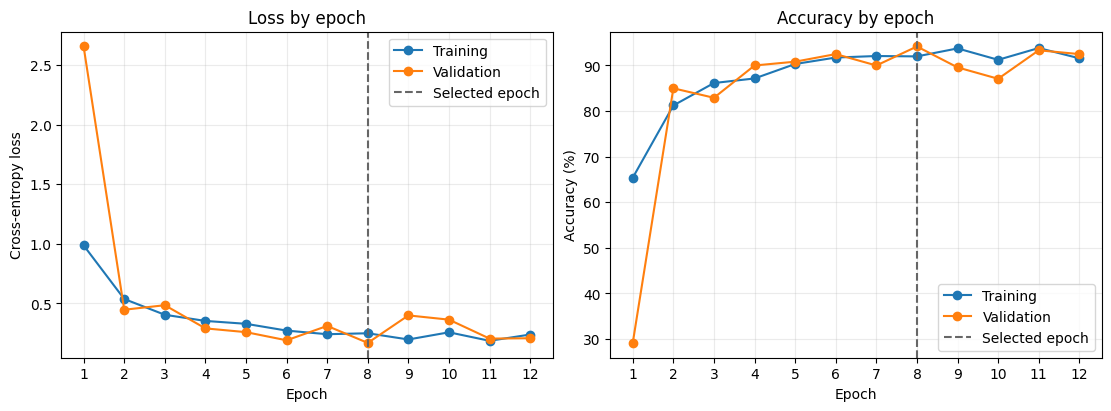

In [14]:
epochs = np.arange(1, epoch_number + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

axes[0].plot(epochs, train_losses, marker="o", label="Training")
axes[0].plot(epochs, val_losses, marker="o", label="Validation")
axes[0].set(title="Loss by epoch", ylabel="Cross-entropy loss")

axes[1].plot(epochs, np.asarray(train_accuracies) * 100, marker="o", label="Training")
axes[1].plot(epochs, np.asarray(val_accuracies) * 100, marker="o", label="Validation")
axes[1].set(title="Accuracy by epoch", ylabel="Accuracy (%)")

for ax in axes:
    ax.axvline(best_epoch, linestyle="--", color="0.4", label="Selected epoch")
    ax.set(xlabel="Epoch", xticks=epochs)
    ax.legend()
    ax.grid(alpha=0.25)

plt.show()

7. Save and reload the weights

The weights from the selected epoch go into a `.pth` file. I load that file into a fresh copy of the same CNN and use the reloaded model for prediction and testing.

In [15]:
weights_path = Path("neu_steel_cnn_weights.pth")
torch.save(best_weights, weights_path)

size_mb = weights_path.stat().st_size / 1_000_000
print(f"Saved {weights_path.name} ({size_mb:.3f} MB)")

Saved neu_steel_cnn_weights.pth (0.366 MB)


In [16]:
saved_model, _, _ = get_model()
saved_model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
saved_model.eval()
print("Weights loaded into a fresh CNN.")

Weights loaded into a fresh CNN.


8. Predict one image and evaluate the test set

The example below shows the true label, the predicted label, and the model's softmax score for its prediction. The next cell measures overall accuracy and macro F1, which gives each class equal weight.

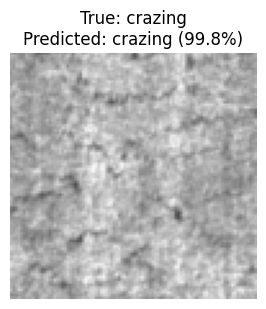

In [17]:
@torch.no_grad()
def predict_one(model, image):
    output = model(image.unsqueeze(0).to(device))
    confidence, class_id = output.softmax(dim=1).max(dim=1)
    return class_names[class_id.item()], confidence.item()


test_image, label = test_data[2]
predicted_name, confidence = predict_one(saved_model, test_image)

plt.figure(figsize=(3.2, 3.2))
plt.imshow((test_image.squeeze(0) * 0.5 + 0.5), cmap="gray", vmin=0, vmax=1)
plt.title(f"True: {class_names[label]}\nPredicted: {predicted_name} ({confidence:.1%})")
plt.axis("off")
plt.show()

Test loss: 0.2853
Test accuracy: 89.44%
Correct predictions: 322/360
Test macro F1: 0.8924
                 precision    recall  f1-score   support

        crazing     0.9524    1.0000    0.9756        60
      inclusion     0.8913    0.6833    0.7736        60
        patches     0.9048    0.9500    0.9268        60
 pitted surface     0.7463    0.8333    0.7874        60
rolled-in scale     0.9677    1.0000    0.9836        60
      scratches     0.9153    0.9000    0.9076        60

       accuracy                         0.8944       360
      macro avg     0.8963    0.8944    0.8924       360
   weighted avg     0.8963    0.8944    0.8924       360



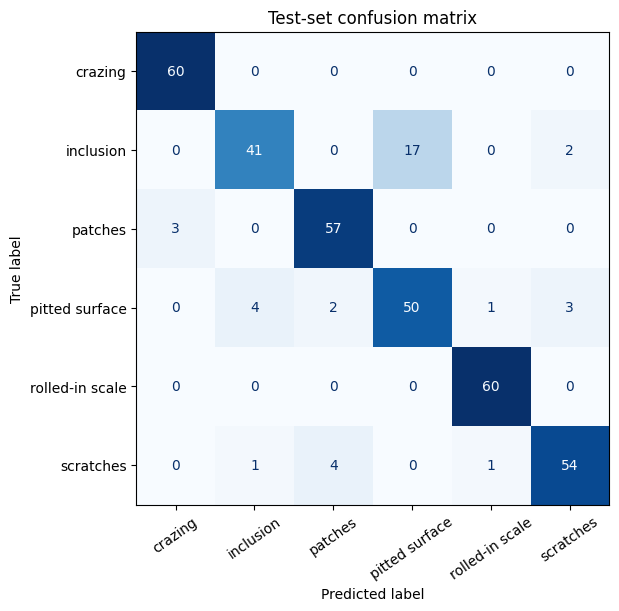

In [18]:
test_loss, test_acc = validation(test_dl, saved_model, loss_fn)

y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_dl:
        prediction = saved_model(x.to(device))
        y_true.extend(y.tolist())
        y_pred.extend(prediction.argmax(dim=1).cpu().tolist())

class_ids = list(range(len(class_names)))
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Correct predictions: {sum(a == b for a, b in zip(y_true, y_pred))}/{len(y_true)}")
print(f"Test macro F1: {f1_score(y_true, y_pred, average='macro', labels=class_ids):.4f}")
print(classification_report(
    y_true, y_pred, labels=class_ids, target_names=class_names, digits=4, zero_division=0
))

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=class_ids, display_labels=class_names,
    ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=35
)
ax.set_title("Test-set confusion matrix")
plt.show()

9. Discussion and conclusion

Results

I tested the CNN on 360 steel surface images, with 60 images for each of the six defect types. The model got 322 images right, giving a test accuracy of 89.44%. The test loss was 0.2853, and the macro F1-score was 0.8924.

What stood out was how much the results varied by defect type. The model correctly identified all 60 images of crazing and all 60 images of rolled-in scale. It had more trouble with inclusion, getting only 41 of the 60 images right. It also predicted pitted surface 67 times, but only 50 of those predictions were correct. This means the overall accuracy gives only part of the picture. The model was much more reliable for some defects than for others.